# Step 4 - Model training (house_1, microwave) - with context features
Features per reading: `power`, `delta` (change from previous), `roll_mean`, `roll_std` (last 10 readings, about 60 s).
The context features let the models see a *sustained* abnormal level, not just a single jump.
Train = TRAIN split, steady ON-state readings (running now and in the previous reading). Scaler fitted on train only.
LOF/OCSVM use a fixed random sample (max 5000 rows, seed 42); LOF gets tiny jitter (1e-3) because repeated identical rows break LOF.

In [ ]:
import os, sys, time, pickle, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sys.path.append("..")
from features import add_features, FEATS, live_features
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
SEED = 42; rng = np.random.default_rng(SEED); sns.set_theme()
APP, THRESH, MAX_FIT, CONTAM = "microwave", 20, 5000, 0.02
os.makedirs("../models", exist_ok=True)
df = add_features(pd.read_csv(f"../data/{APP}_clean.csv", index_col=0, parse_dates=True))
steady = df.active & df.active.shift(1, fill_value=False)
Xtr = df.loc[(df.split == "train") & steady, FEATS].values; Xte = df.loc[(df.split == "test") & steady, FEATS].values
print("train rows:", len(Xtr), "| test rows:", len(Xte))

train rows: 5310 | test rows: 751


## 4.1 Train the three models and save them

In [ ]:
def make(name):
    return {"IF": IsolationForest(n_estimators=200, contamination=CONTAM, random_state=SEED),
            "LOF": LocalOutlierFactor(n_neighbors=30, contamination=CONTAM, novelty=True),
            "OCSVM": OneClassSVM(nu=CONTAM, gamma="scale")}[name]
sc = StandardScaler().fit(Xtr); Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)
typical = {"median": float(np.median(Xtr[:, 0])), "p99": float(np.percentile(Xtr[:, 0], 99))}
rows, preds = [], {}
for name in ["IF", "LOF", "OCSVM"]:
    sub = Xtr_s if name == "IF" else Xtr_s[rng.choice(len(Xtr_s), min(MAX_FIT, len(Xtr_s)), replace=False)]
    if name == "LOF": sub = sub + rng.normal(0, 1e-3, sub.shape)
    m = make(name); t = time.time(); m.fit(sub); fit_s = time.time() - t
    t = time.time(); p = m.predict(Xte_s); pred_s = time.time() - t; preds[name] = p
    joblib.dump({"model": m, "scaler": sc, "threshold": THRESH, "typical": typical}, f"../models/{APP}_{name}.joblib")
    rows.append(dict(model=name, fit_rows=len(sub), fit_s=round(fit_s, 3), predict_s=round(pred_s, 3),
                     flagged_normal_test_pct=round(float((p == -1).mean() * 100), 2), size_KB=round(len(pickle.dumps(m)) / 1024, 1)))
log = pd.DataFrame(rows); log.to_csv("../data/training_log.csv", index=False); print(typical); log

{'median': 1330.0, 'p99': 1632.0}


,model,fit_rows,fit_s,predict_s,flagged_normal_test_pct,size_KB
0,IF,5310,0.310,0.019,1.60,2779.3
1,LOF,5000,0.060,0.009,2.26,1470.4
2,OCSVM,5000,0.026,0.005,3.46,5.7


## 4.2 Cost comparison

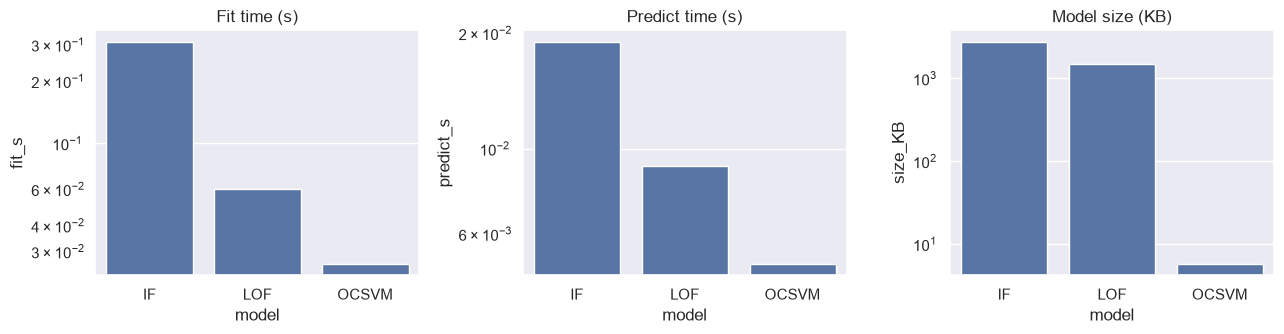

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for a_, c, t in zip(ax, ["fit_s", "predict_s", "size_KB"], ["Fit time (s)", "Predict time (s)", "Model size (KB)"]):
    sns.barplot(data=log, x="model", y=c, ax=a_); a_.set_yscale("log"); a_.set_title(t)
plt.tight_layout(); plt.savefig("../data/fig_model_cost.png", dpi=120); plt.show()

## 4.3 What Isolation Forest flags on normal test data (red)

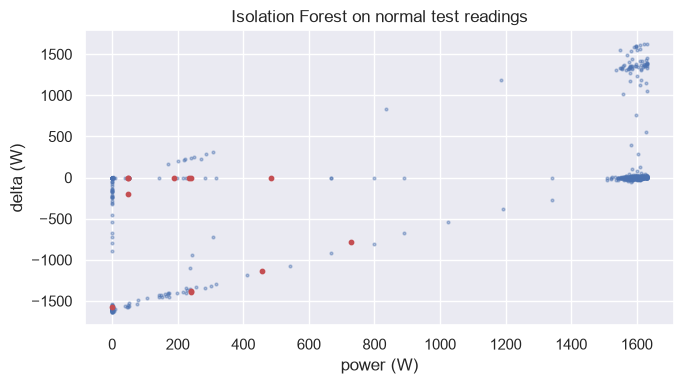

In [ ]:
flag = preds["IF"] == -1; s = rng.choice(len(Xte), min(15000, len(Xte)), replace=False); f = flag[s]
plt.figure(figsize=(7, 4)); plt.scatter(Xte[s][~f, 0], Xte[s][~f, 1], s=4, alpha=.4); plt.scatter(Xte[s][f, 0], Xte[s][f, 1], s=10, c="r")
plt.xlabel("power (W)"); plt.ylabel("delta (W)"); plt.title("Isolation Forest on normal test readings"); plt.tight_layout()
plt.savefig("../data/fig_if_flagged.png", dpi=120); plt.show()

## 4.4 Choosing the contamination parameter (Isolation Forest)

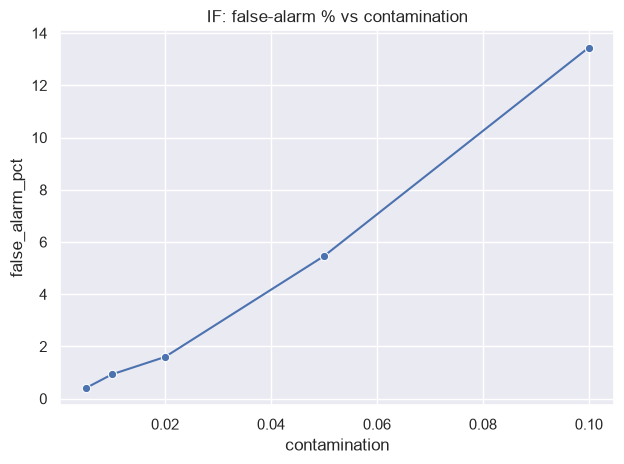

,contamination,false_alarm_pct
0,0.005,0.399467
1,0.010,0.932091
2,0.020,1.597870
3,0.050,5.459387
4,0.100,13.448735


In [ ]:
sens = pd.DataFrame([dict(contamination=c, false_alarm_pct=float((IsolationForest(n_estimators=200, contamination=c, random_state=SEED)
        .fit(Xtr_s).predict(Xte_s) == -1).mean() * 100)) for c in [0.005, 0.01, 0.02, 0.05, 0.1]])
sns.lineplot(data=sens, x="contamination", y="false_alarm_pct", marker="o"); plt.title("IF: false-alarm % vs contamination")
plt.tight_layout(); plt.savefig("../data/fig_contamination.png", dpi=120); plt.show(); sens

## 4.5 Sanity check: normal -> sustained spike -> normal (A = anomaly, . = normal)

In [ ]:
typ = typical["median"]; seq = [typ] * 12 + [typ * 2.2] * 6 + [typ] * 12
for n in ["IF", "LOF", "OCSVM"]:
    b = joblib.load(f"../models/{APP}_{n}.joblib"); buf, out = [], ""
    for p in seq:
        out += "A" if b["model"].predict(b["scaler"].transform([live_features(buf, p)]))[0] == -1 else "."; buf.append(p)
    print(f"{n:6s}", out)
print("       12 normal | 6 spike | 12 normal")

IF     ............A.....A...........
LOF    .............AAAAAAAAAAAAA....
OCSVM  ............AAAAAAAAAAAAAA....
       12 normal | 6 spike | 12 normal
